Upload bank_marketing_train_clean.csv


Saving bank_marketing_train_clean.csv to bank_marketing_train_clean.csv

Dataset loaded successfully!
Rows: 45,211
Columns: 19


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,previously_contacted,target
0,58,management,married,tertiary,no,2143,yes,no,not_provided,5,may,261,1,0,0,not_previously_contacted,no,no,0
1,44,technician,single,secondary,no,29,yes,no,not_provided,5,may,151,1,0,0,not_previously_contacted,no,no,0
2,33,entrepreneur,married,secondary,no,2,yes,yes,not_provided,5,may,76,1,0,0,not_previously_contacted,no,no,0
3,47,blue-collar,married,not_provided,no,1506,yes,no,not_provided,5,may,92,1,0,0,not_previously_contacted,no,no,0
4,33,not_provided,single,not_provided,no,1,no,no,not_provided,5,may,198,1,0,0,not_previously_contacted,no,no,0



CUSTOMER CHARACTERISTICS - DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max,mode,median
age,45211.0,40.94,10.62,18.0,33.0,39.0,48.0,95.0,32,39.0
balance,45211.0,1362.27,3044.77,-8019.0,72.0,448.0,1428.0,102127.0,0,448.0



CATEGORICAL CUSTOMER DISTRIBUTIONS

JOB DISTRIBUTION


... (9 outputs left out)


CATEGORICAL SUMMARY


,Characteristic,Mode,Unique Categories
0,job,blue-collar,12
1,marital,married,3
2,education,secondary,4
3,housing,yes,2
4,loan,no,2



AGE GROUP DISTRIBUTION


,Age Group,Customers,Percentage
0,18-25,1336,2.96
1,26-35,15571,34.44
2,36-45,13856,30.65
3,46-55,9548,21.12
4,56-65,4149,9.18
5,66+,751,1.66


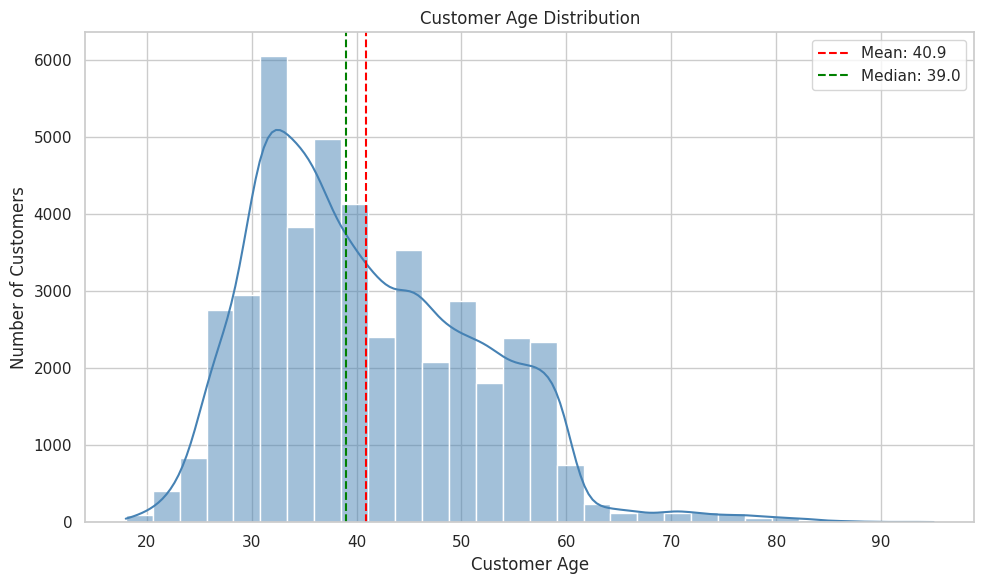

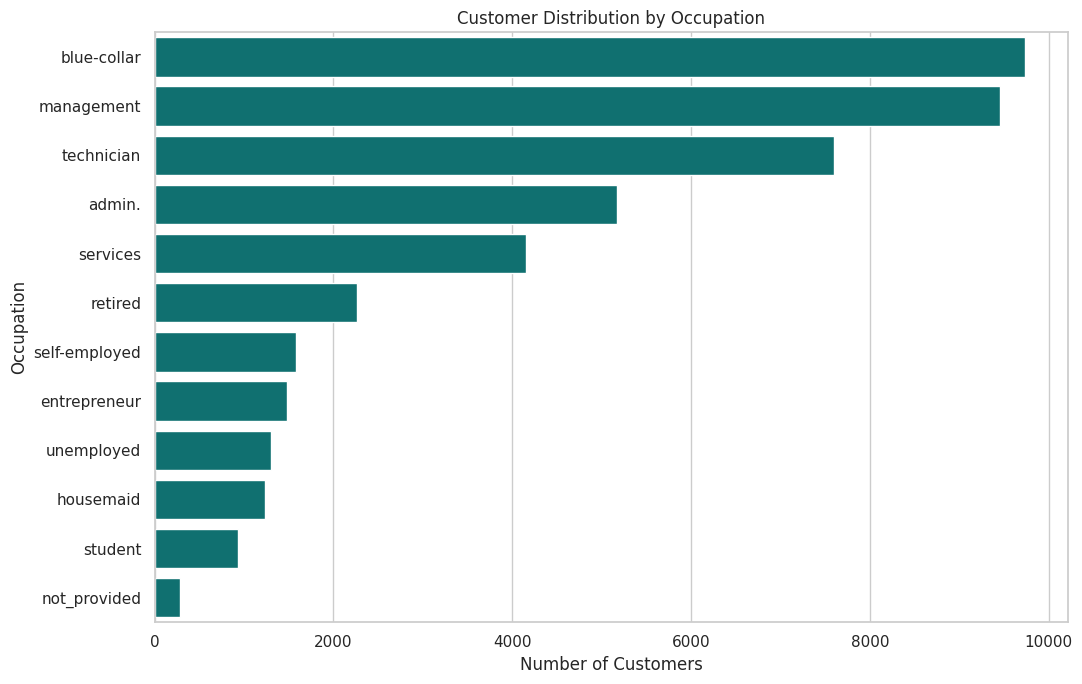

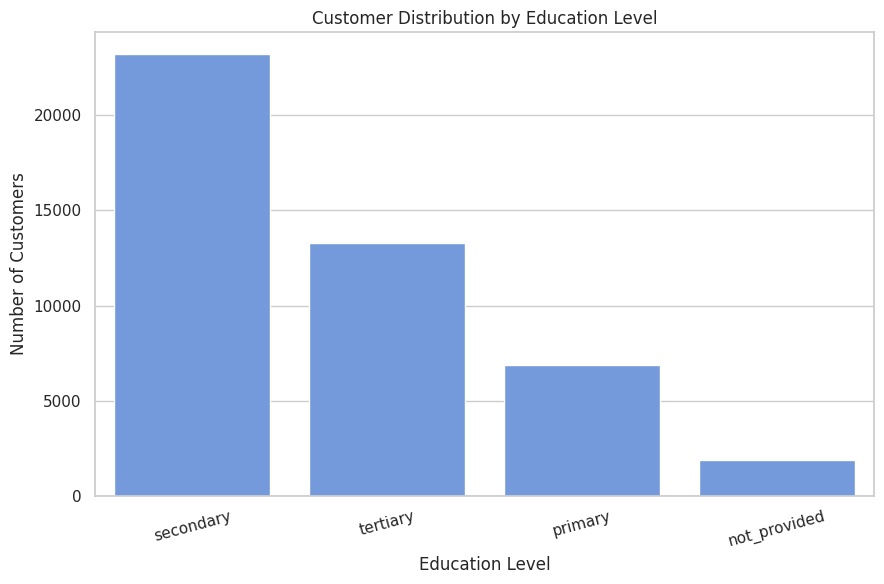

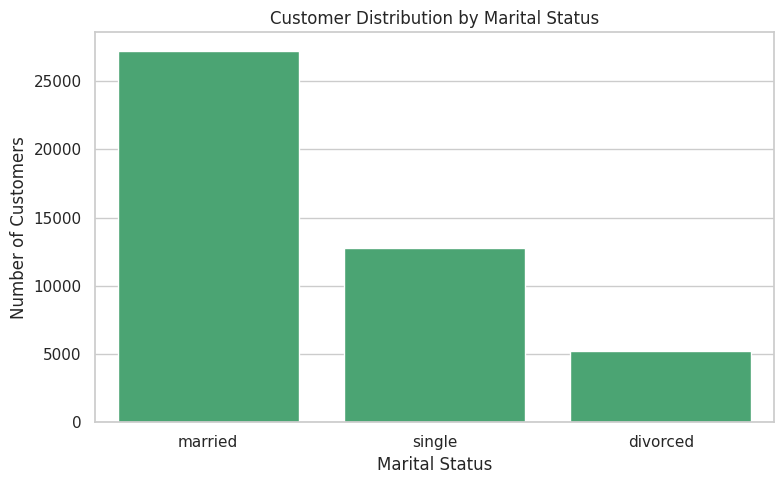

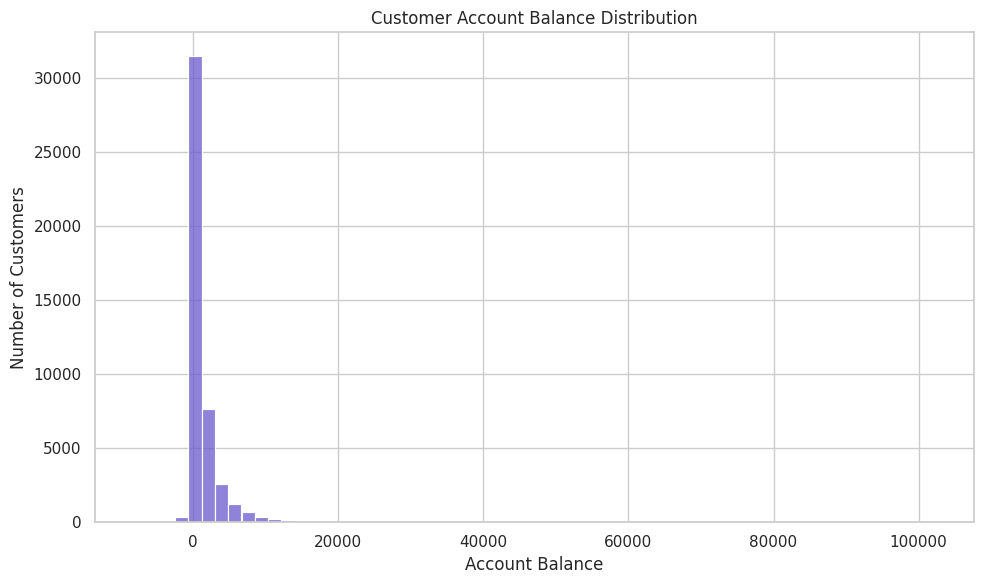

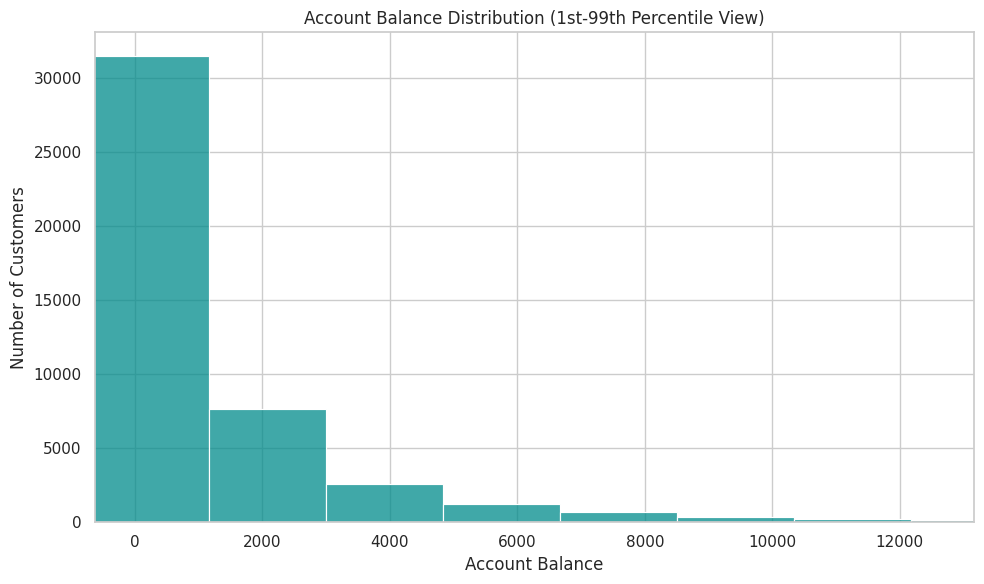

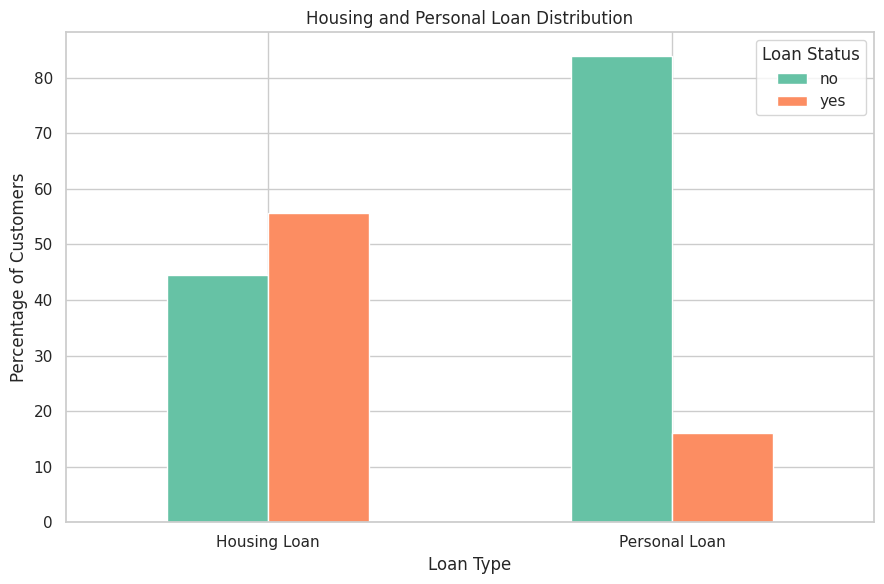


CUSTOMER RESPONSE RATES

RESPONSE RATE BY AGE_GROUP


,age_group,Total_Customers,Subscriptions,Response_Rate
5,66+,751,320,42.61
0,18-25,1336,320,23.95
4,56-65,4149,586,14.12
1,26-35,15571,1869,12.00
2,36-45,13856,1301,9.39
3,46-55,9548,893,9.35



RESPONSE RATE BY JOB


,job,Total_Customers,Subscriptions,Response_Rate
9,student,938,269,28.68
6,retired,2264,516,22.79
11,unemployed,1303,202,15.50
4,management,9458,1301,13.76
0,admin.,5171,631,12.20
7,self-employed,1579,187,11.84
5,not_provided,288,34,11.81
10,technician,7597,840,11.06
8,services,4154,369,8.88
3,housemaid,1240,109,8.79



RESPONSE RATE BY EDUCATION


,education,Total_Customers,Subscriptions,Response_Rate
3,tertiary,13301,1996,15.01
0,not_provided,1857,252,13.57
2,secondary,23202,2450,10.56
1,primary,6851,591,8.63


... (2 outputs left out)


RESPONSE RATE BY HOUSING


,housing,Total_Customers,Subscriptions,Response_Rate
0,no,20081,3354,16.7
1,yes,25130,1935,7.7



RESPONSE RATE BY LOAN


,loan,Total_Customers,Subscriptions,Response_Rate
0,no,37967,4805,12.66
1,yes,7244,484,6.68


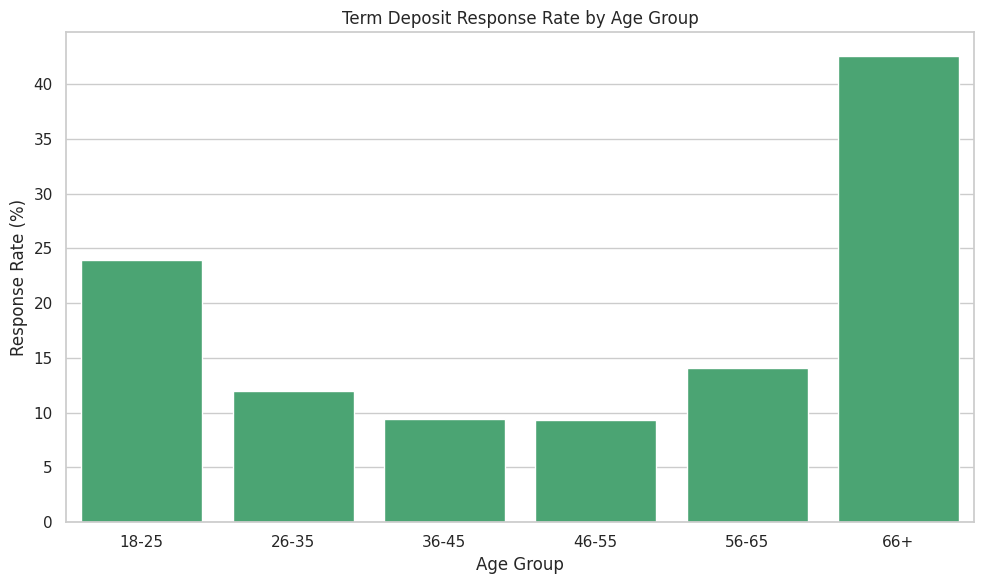

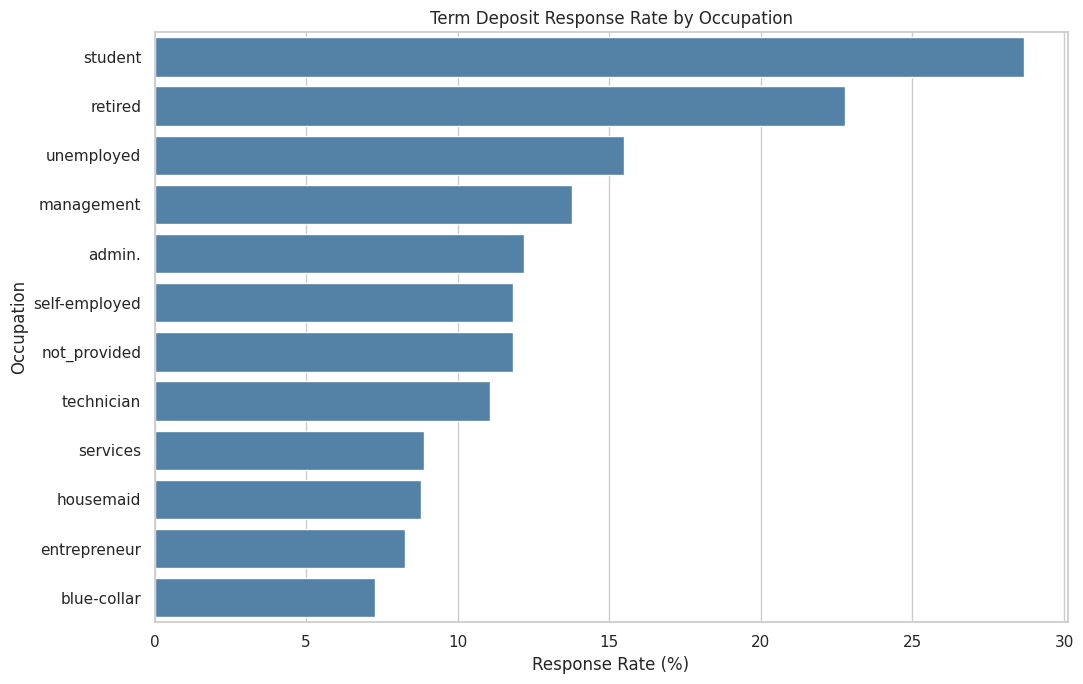


OUTLIER ANALYSIS


,Variable,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
0,age,33.0,48.0,15.0,10.5,70.5,487,1.08
1,balance,72.0,1428.0,1356.0,-1962.0,3462.0,4729,10.46


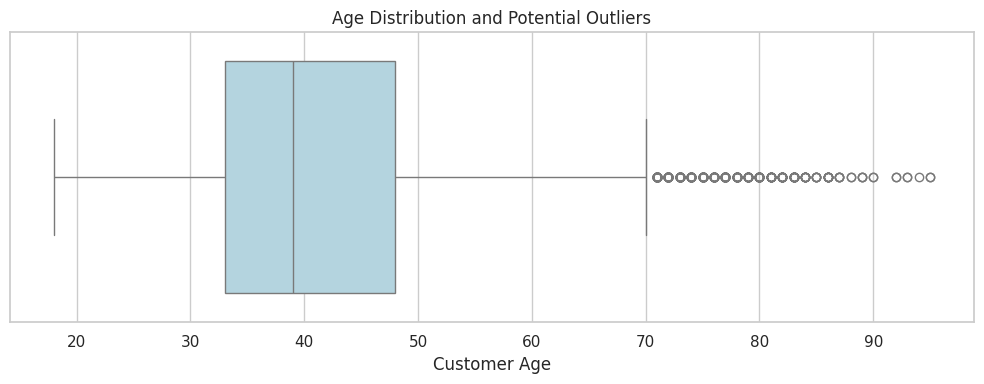

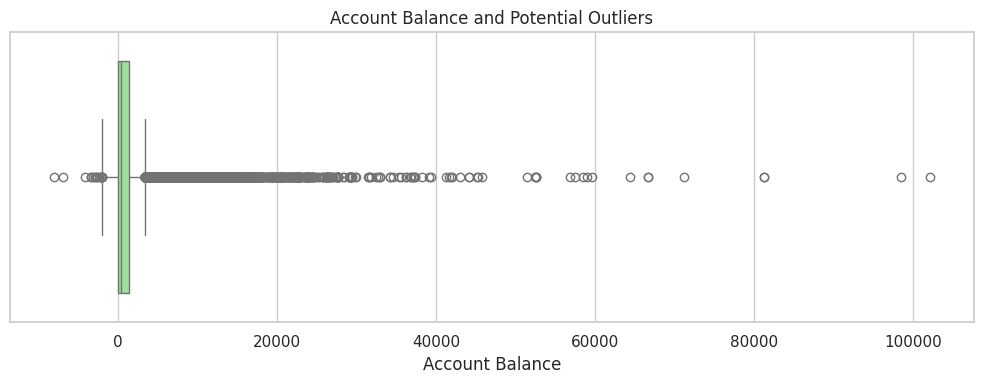


KEY CUSTOMER CHARACTERISTICS - FINDINGS

CUSTOMER DEMOGRAPHICS
---------------------
Total Customers: 45,211

Average Age: 40.94
Median Age: 39.00
Most Common Age: 32

Most Common Occupation: blue-collar
Most Common Education: secondary
Most Common Marital Status: married

ACCOUNT BALANCE
---------------
Average Balance: 1,362.27
Median Balance: 448.00
Minimum Balance: -8,019.00
Maximum Balance: 102,127.00

Customers with Negative Balance: 3,766

LOAN CHARACTERISTICS
--------------------
Customers with Housing Loans:
25,130

Customers with Personal Loans:
7,244

MARKETING RESPONSE
------------------
Overall Subscription Response Rate:
11.70%


NOTABLE PATTERNS AND OUTLIERS

1. The most common occupation is blue-collar.

2. The largest customer age group is 26-35.

3. The mean account balance is
   1,362.27, while the median is
   448.00.
   A large difference suggests a skewed distribution.

4. The highest observed occupation response rate is
   28.68% for
   student customers.

5. Th

In [1]:

# Banking Marketing Campaign Analytics Dashboard
# Task: Exploratory Data Analysis on Customer Characteristics
# Dataset: Banking Dataset - Marketing Targets (Kaggle)
# Acceptance Criteria:
# 1. Descriptive statistics for key customer characteristics
# 2. Visualizations for at least 3 customer characteristics
# 3. Identification of notable patterns and outliers


# 1. Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from IPython.display import display

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)

# 2. Upload cleaned training dataset

print("Upload bank_marketing_train_clean.csv")
uploaded = files.upload()

filename = next(
    (name for name in uploaded
     if "train_clean" in name.lower() and name.endswith(".csv")),
    None
)

if filename is None:
    raise FileNotFoundError(
        "Please upload bank_marketing_train_clean.csv"
    )

df = pd.read_csv(filename)

required_columns = [
    "age", "job", "marital", "education",
    "balance", "housing", "loan", "y"
]

missing_columns = [
    col for col in required_columns if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

df["y"] = df["y"].astype(str).str.strip().str.lower()

if not df["y"].isin(["yes", "no"]).all():
    raise ValueError("Unexpected values found in target column y")

df["target"] = df["y"].map({"yes": 1, "no": 0})

print("\nDataset loaded successfully!")
print(f"Rows: {df.shape[0]:,}")
print(f"Columns: {df.shape[1]}")

display(df.head())


# 3. General customer statistics

print("\n" + "=" * 65)
print("CUSTOMER CHARACTERISTICS - DESCRIPTIVE STATISTICS")
print("=" * 65)

numeric_customer_columns = ["age", "balance"]

stats = df[numeric_customer_columns].describe().T

stats["mode"] = [
    df[col].mode().iloc[0]
    for col in numeric_customer_columns
]

stats["median"] = df[numeric_customer_columns].median()

display(stats.round(2))


# 4. Categorical customer distributions


print("\n" + "=" * 65)
print("CATEGORICAL CUSTOMER DISTRIBUTIONS")
print("=" * 65)

categorical_columns = [
    "job", "marital", "education",
    "housing", "loan"
]

categorical_results = []

for column in categorical_columns:

    print(f"\n{column.upper()} DISTRIBUTION")

    counts = df[column].value_counts(dropna=False)

    distribution = pd.DataFrame({
        "Count": counts,
        "Percentage": (
            counts / len(df) * 100
        ).round(2)
    })

    display(distribution)

    mode_value = df[column].mode().iloc[0]

    categorical_results.append({
        "Characteristic": column,
        "Mode": mode_value,
        "Unique Categories": df[column].nunique()
    })

print("\nCATEGORICAL SUMMARY")
display(pd.DataFrame(categorical_results))


# 5. Create age groups

age_bins = [0, 25, 35, 45, 55, 65, np.inf]

age_labels = [
    "18-25", "26-35", "36-45",
    "46-55", "56-65", "66+"
]

df["age_group"] = pd.cut(
    df["age"],
    bins=age_bins,
    labels=age_labels,
    include_lowest=True
)

print("\nAGE GROUP DISTRIBUTION")

age_group_summary = (
    df["age_group"]
    .value_counts(sort=False)
    .rename_axis("Age Group")
    .reset_index(name="Customers")
)

age_group_summary["Percentage"] = (
    age_group_summary["Customers"] / len(df) * 100
).round(2)

display(age_group_summary)

# 6. Visualization 1 - Age distribution

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True,
    color="steelblue"
)

plt.axvline(
    df["age"].mean(),
    color="red",
    linestyle="--",
    label=f"Mean: {df['age'].mean():.1f}"
)

plt.axvline(
    df["age"].median(),
    color="green",
    linestyle="--",
    label=f"Median: {df['age'].median():.1f}"
)

plt.title("Customer Age Distribution")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")
plt.legend()
plt.tight_layout()
plt.savefig("01_age_distribution.png", dpi=150)
plt.show()


# 7. Visualization 2 - Occupation distribution

job_counts = df["job"].value_counts()

plt.figure(figsize=(11, 7))

sns.barplot(
    x=job_counts.values,
    y=job_counts.index,
    color="teal"
)

plt.title("Customer Distribution by Occupation")
plt.xlabel("Number of Customers")
plt.ylabel("Occupation")
plt.tight_layout()
plt.savefig("02_occupation_distribution.png", dpi=150)
plt.show()


# 8. Visualization 3 - Education distribution

education_counts = df["education"].value_counts()

plt.figure(figsize=(9, 6))

sns.barplot(
    x=education_counts.index,
    y=education_counts.values,
    color="cornflowerblue"
)

plt.title("Customer Distribution by Education Level")
plt.xlabel("Education Level")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig("03_education_distribution.png", dpi=150)
plt.show()



# 9. Visualization 4 - Marital status


marital_counts = df["marital"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=marital_counts.index,
    y=marital_counts.values,
    color="mediumseagreen"
)

plt.title("Customer Distribution by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("04_marital_distribution.png", dpi=150)
plt.show()


# 10. Visualization 5 - Account balance

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="balance",
    bins=60,
    color="slateblue"
)

plt.title("Customer Account Balance Distribution")
plt.xlabel("Account Balance")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("05_balance_distribution.png", dpi=150)
plt.show()

# Account balances may have extreme values.
# Display a zoomed view without removing any observations
# from the underlying dataset.

lower = df["balance"].quantile(0.01)
upper = df["balance"].quantile(0.99)

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="balance",
    bins=60,
    color="darkcyan"
)

plt.xlim(lower, upper)
plt.title("Account Balance Distribution (1st-99th Percentile View)")
plt.xlabel("Account Balance")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.savefig("06_balance_zoomed.png", dpi=150)
plt.show()



# 11. Visualization 6 - Housing and personal loans

loan_summary = pd.DataFrame({
    "Housing Loan": df["housing"].value_counts(normalize=True),
    "Personal Loan": df["loan"].value_counts(normalize=True)
}).fillna(0) * 100

loan_summary.T.plot(
    kind="bar",
    figsize=(9, 6)
)

plt.title("Housing and Personal Loan Distribution")
plt.xlabel("Loan Type")
plt.ylabel("Percentage of Customers")
plt.xticks(rotation=0)
plt.legend(title="Loan Status")
plt.tight_layout()
plt.savefig("07_loan_distribution.png", dpi=150)
plt.show()



# 12. Customer response rates by characteristics

print("\n" + "=" * 65)
print("CUSTOMER RESPONSE RATES")
print("=" * 65)

# The target column represents subscription to a term deposit.
# Response Rate = Customers with y = yes / Total customers * 100

response_columns = [
    "age_group", "job", "education",
    "marital", "housing", "loan"
]

response_tables = {}

for column in response_columns:

    summary = (
        df.groupby(column, observed=True)
        .agg(
            Total_Customers=("target", "size"),
            Subscriptions=("target", "sum"),
            Response_Rate=("target", "mean")
        )
        .reset_index()
    )

    summary["Response_Rate"] = (
        summary["Response_Rate"] * 100
    ).round(2)

    summary = summary.sort_values(
        "Response_Rate",
        ascending=False
    )

    response_tables[column] = summary

    print(f"\nRESPONSE RATE BY {column.upper()}")
    display(summary)



# 13. Visualization 7 - Response rate by age group

age_response = response_tables["age_group"].copy()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=age_response,
    x="age_group",
    y="Response_Rate",
    color="mediumseagreen",
    order=age_labels
)

plt.title("Term Deposit Response Rate by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Response Rate (%)")
plt.tight_layout()
plt.savefig("08_response_rate_by_age.png", dpi=150)
plt.show()



# 14. Visualization 8 - Response rate by occupation


job_response = response_tables["job"]

plt.figure(figsize=(11, 7))

sns.barplot(
    data=job_response,
    x="Response_Rate",
    y="job",
    color="steelblue"
)

plt.title("Term Deposit Response Rate by Occupation")
plt.xlabel("Response Rate (%)")
plt.ylabel("Occupation")
plt.tight_layout()
plt.savefig("09_response_rate_by_job.png", dpi=150)
plt.show()



# 15. Outlier detection using IQR


print("\n" + "=" * 65)
print("OUTLIER ANALYSIS")
print("=" * 65)

# IQR = Q3 - Q1
# Lower Bound = Q1 - 1.5 * IQR
# Upper Bound = Q3 + 1.5 * IQR

outlier_columns = ["age", "balance"]

outlier_results = []

for column in outlier_columns:

    q1 = df[column].quantile(0.25)
    q3 = df[column].quantile(0.75)

    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = df[
        (df[column] < lower_bound) |
        (df[column] > upper_bound)
    ]

    outlier_results.append({
        "Variable": column,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": len(outliers),
        "Outlier Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_summary = pd.DataFrame(outlier_results)

display(outlier_summary)



# 16. Visualization 9 - Age box plot


plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["age"],
    color="lightblue"
)

plt.title("Age Distribution and Potential Outliers")
plt.xlabel("Customer Age")
plt.tight_layout()
plt.savefig("10_age_boxplot.png", dpi=150)
plt.show()



# 17. Visualization 10 - Balance box plot


plt.figure(figsize=(10, 4))

sns.boxplot(
    x=df["balance"],
    color="lightgreen"
)

plt.title("Account Balance and Potential Outliers")
plt.xlabel("Account Balance")
plt.tight_layout()
plt.savefig("11_balance_boxplot.png", dpi=150)
plt.show()



# 18. Identify notable patterns


print("\n" + "=" * 65)
print("KEY CUSTOMER CHARACTERISTICS - FINDINGS")
print("=" * 65)

most_common_job = df["job"].mode().iloc[0]
most_common_education = df["education"].mode().iloc[0]
most_common_marital = df["marital"].mode().iloc[0]

overall_response = df["target"].mean() * 100

negative_balance_count = (df["balance"] < 0).sum()

print(f"""
CUSTOMER DEMOGRAPHICS
---------------------
Total Customers: {len(df):,}

Average Age: {df['age'].mean():.2f}
Median Age: {df['age'].median():.2f}
Most Common Age: {df['age'].mode().iloc[0]}

Most Common Occupation: {most_common_job}
Most Common Education: {most_common_education}
Most Common Marital Status: {most_common_marital}

ACCOUNT BALANCE
---------------
Average Balance: {df['balance'].mean():,.2f}
Median Balance: {df['balance'].median():,.2f}
Minimum Balance: {df['balance'].min():,.2f}
Maximum Balance: {df['balance'].max():,.2f}

Customers with Negative Balance: {negative_balance_count:,}

LOAN CHARACTERISTICS
--------------------
Customers with Housing Loans:
{(df['housing'] == 'yes').sum():,}

Customers with Personal Loans:
{(df['loan'] == 'yes').sum():,}

MARKETING RESPONSE
------------------
Overall Subscription Response Rate:
{overall_response:.2f}%
""")



# 19. Automatically generate analytical findings


print("\n" + "=" * 65)
print("NOTABLE PATTERNS AND OUTLIERS")
print("=" * 65)

top_job = df["job"].value_counts().idxmax()

top_age_group = (
    df["age_group"]
    .value_counts()
    .idxmax()
)

highest_job_response = (
    response_tables["job"]
    .iloc[0]
)

highest_age_response = (
    response_tables["age_group"]
    .iloc[0]
)

age_outliers = outlier_summary.loc[
    outlier_summary["Variable"] == "age",
    "Outlier Count"
].iloc[0]

balance_outliers = outlier_summary.loc[
    outlier_summary["Variable"] == "balance",
    "Outlier Count"
].iloc[0]

print(f"""
1. The most common occupation is {top_job}.

2. The largest customer age group is {top_age_group}.

3. The mean account balance is
   {df['balance'].mean():,.2f}, while the median is
   {df['balance'].median():,.2f}.
   A large difference suggests a skewed distribution.

4. The highest observed occupation response rate is
   {highest_job_response['Response_Rate']:.2f}% for
   {highest_job_response['job']} customers.

5. The highest observed age-group response rate is
   {highest_age_response['Response_Rate']:.2f}% for
   the {highest_age_response['age_group']} age group.

6. Potential age outliers detected: {age_outliers:,}.

7. Potential balance outliers detected: {balance_outliers:,}.

8. Negative balances and extreme positive balances are
   plausible banking values and should not automatically
   be removed.

9. These results describe associations and distributions,
   not causal relationships.
""")



# 20. Export analysis results


stats.to_csv("customer_descriptive_statistics.csv")

outlier_summary.to_csv(
    "customer_outlier_summary.csv",
    index=False
)

age_group_summary.to_csv(
    "customer_age_group_distribution.csv",
    index=False
)

for column, table in response_tables.items():

    table.to_csv(
        f"customer_response_by_{column}.csv",
        index=False
    )



# 21. Final completion summary


print("\n" + "=" * 65)
print("EDA TASK COMPLETED")
print("=" * 65)

print("""
Acceptance Criteria Completed:

1. Descriptive statistics generated for key customer
   characteristics, including age, balance, occupation,
   education, marital status, and loans.

2. More than three customer characteristics visualized
   using histograms, bar charts, and box plots.

3. Potential outliers identified using the IQR method.

4. Customer response rates compared across demographic
   and behavioral characteristics.

5. Summary findings generated automatically.

6. Charts and summary tables exported for documentation
   and dashboard development.

The exploratory analysis is complete and ready for review.
""")